In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import scipy
import glob
import pathlib
import datetime
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
import string
letters = string.ascii_lowercase

import helpers
import plot_helpers
import analytical

paperdir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/figures/paper')
paperdir.mkdir(parents=1, exist_ok=1)

#### LOAD

In [2]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L2_test_model_change')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds = xr.concat(li, dim='system')

In [3]:
# filter data

gsystems = ds.max_CMF.dropna('system').system
ds = ds.sel(system=gsystems)
ds = ds.where(ds.category=='isolated').dropna('system', how='all')
print('We have', ds.system.size, 'isolated DCCs')

ds = ds.where(ds.lifestages_valid).dropna('system', how='all')
print('Of these,', ds.system.size, 'had all valid lifestages')

We have 4503 isolated DCCs
Of these, 4335 had all valid lifestages


In [4]:
# calculate intensity quartiles

intensity_measures = ['total_CMT','max_CMT','max_CMF','max_w','max_Ac','conv_lifetime']
df = helpers.dccs_by_intensity_metrics(ds, ds[intensity_measures])

In [5]:
# define a global colormap
CMAP = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.25,1,265)))

# choices
dpi = 300
ext = 'pdf'
fs = 12
key = 'total_CMT'

# labels for key variables
global_labels = {"total_CMT":r"$\int M_c dt\,$",
                 "max_CMT":r"$M_{c,max}$",
                 "max_CMF":r"$(\rho w)_{max}$",
                 "max_w":"Maximum updraft",
                 "max_Ac":"Maximum core area",
                 "conv_lifetime":"Duration of convection",
                 # "Apred_v1": r"$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$ cont.",
                 # "Apred_v1_conv": r"$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$",
                 # "Apred_v3_conv": r"$\int \frac{M_c}{D\bar{\rho}}\,dt$",
                 # "Apred_v3_cont": r"$\int \frac{M_c}{D\bar{\rho}}\,dt$ cont.",
                 # "Apred_v1": r"$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$ cont.",
                 # "Apred_v1_conv":r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
                 # "Apred_v3_conv":r'$\int \frac{M_c}{D\bar{\rho}}\,dt$',
                 "Apred_v1":r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
                 "Apred_v2":r'$\int \frac{M_c}{D\bar{\rho}}\,dt$',
                }

#### FIGURE 1

In [3]:
# load snapshot

results_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics')
map_ds = xr.open_mfdataset(results_dir.glob('*/*system_tracks_linked.nc')).isel(time=slice(0,None))
map_ds = map_ds.where(map_ds>0)

utc = '202107011800'
ice = map_ds.system
pdata = ice.sel(time=utc).expand_dims('time')
pdata = pdata.compute()

In [4]:
# plot prep

map_dpi = 100

def make_repeated_tab20_colorbar(x):
    base = plt.get_cmap("tab20").colors
    colors = [base[i % len(base)] for i in range(x)]
    cmap = mpl.colors.ListedColormap(colors, name=f"repeated_tab20_{x}")
    norm = mpl.colors.BoundaryNorm(np.arange(-0.5, x + 0.5, 1), cmap.N)
    return cmap

vmax = pdata.max().values
cmap = make_repeated_tab20_colorbar(int(vmax))

INFO:root:Region to regrid: (34.09999999998783, 37.59999999998764, -0.7000000000000508, 1.0999999999999432)
INFO:root:Region to regrid: (34.09999999998783, 37.59999999998764, -0.7000000000000508, 1.0999999999999432)
INFO:root:Region to regrid: (34.09999999998783, 37.59999999998764, -0.7000000000000508, 1.0999999999999432)


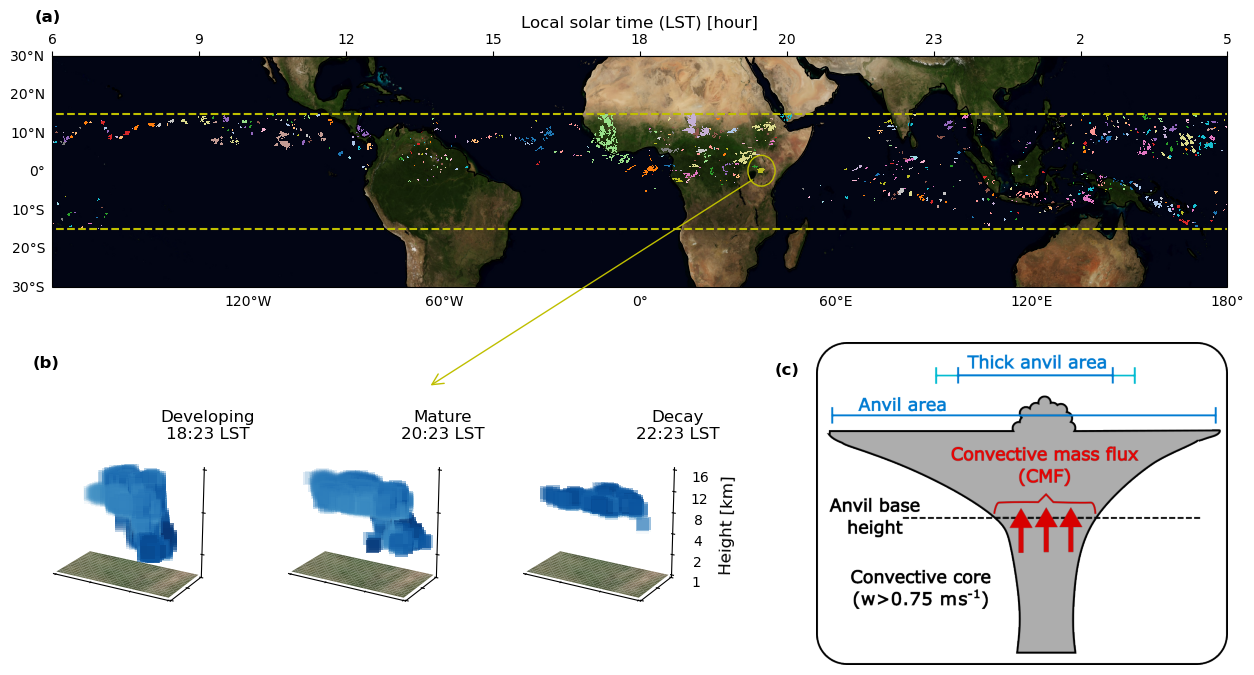

In [5]:
# plot

tstr = pdata.sel(time=utc).time.dt.strftime('%Y%m%dT%H%M').item()
fpath = paperdir / f'fig01_{tstr}.{ext}'
    
# --- layout ---
proj = ccrs.Robinson()
nlon = 360
nlat = 60
scale = 0.05
fig, ax = plt.subplots(figsize=(nlon*scale, nlat*scale), subplot_kw=dict(projection=proj))

## 1. plot tropics
ax = plot_helpers.make_map(ax, pdata, utc, cmap, vmax, fs)
ax.text(-.015, 1.15, '(a)', fontsize=fs, weight='bold', c='k', transform=ax.transAxes)

## 2. show example
t1 = datetime.datetime.strptime(utc, '%Y%m%d%H%M')
t0 = t1 - datetime.timedelta(hours=2)
t2 = t1 + datetime.timedelta(hours=2)

sidx = 3876
example_data = ice.sel(time=[t0,t1,t2])
example_data = example_data.where(example_data == sidx).dropna('lat', how='all').dropna('lon', how='all')

dws = [0,0,0]
dcs = [1,1,1]
name = ("Developing", "Mature", "Decay")
for j, t in enumerate((t0,t1,t2)):
    # axes
    pc = ccrs.PlateCarree()
    bbox = ax.get_position()
    inset_w = bbox.width / 3 * 0.6
    inset_h = bbox.height * .8
    inset_x = bbox.x0 + inset_w * j - .025
    inset_y = bbox.y0 - 1.1
    inset_ax = fig.add_axes([inset_x, inset_y, inset_w, inset_h], projection='3d')
    if not j:
        inset_ax.text2D(0, 1.35, '(b)', fontsize=fs, weight='bold', c='k', transform=inset_ax.transAxes)
    # data
    d = example_data.sel(time=t).expand_dims('time')
    inset_ax = plot_helpers.make_example(inset_ax, d, t, show_dc=dcs[j], show_dw=dws[j], zaxis=j==2, haxis=0, name=name[j])
    inset_ax.set_xlim(d.lon.min(), d.lon.max())
    inset_ax.set_ylim(d.lat.min(), d.lat.max())
    
# circle
radius = 4
clon = example_data.lon.mean()
clat = example_data.lat.mean()
ax.add_patch(Circle((clon, clat), radius=radius, transform=pc, fill=False, ec='y', lw=1, zorder=20,))

# line
pt_data = proj.transform_point(clon-radius/2, clat-radius/2, pc)
pt_disp = ax.transData.transform(pt_data)
pt_fig = fig.transFigure.inverted().transform(pt_disp)
inset_pos = inset_ax.get_position()
x2 = bbox.x0 + inset_w * 1.6
y2 = inset_pos.y1 + .15
fig.add_artist(mpl.patches.FancyArrowPatch((pt_fig[0], pt_fig[1]),(x2, y2), transform=fig.transFigure, arrowstyle='->', color='y', mutation_scale=20, zorder=15,))

## 3. show method

img = plt.imread("/home/b/b382635/s/my_notebooks/model_paper/grl_submission/scripts/fig01_diagram.png")

bbox = ax.get_position()
inset_w = bbox.width * 0.35
inset_h = bbox.height * 1.5
inset_x = bbox.x1 - inset_w
inset_y = bbox.y0 - 1.3
ax_img = fig.add_axes([inset_x, inset_y, inset_w, inset_h])
ax_img.imshow(img)
ax_img.axis('off')
ax_img.text(-.1, .9, '(c)', fontsize=fs, weight='bold', c='k', transform=ax_img.transAxes)

## 4. SAVE
fig.savefig(paperdir / f'fig01.{ext}', dpi=map_dpi, bbox_inches='tight')

#### FIGURE 2

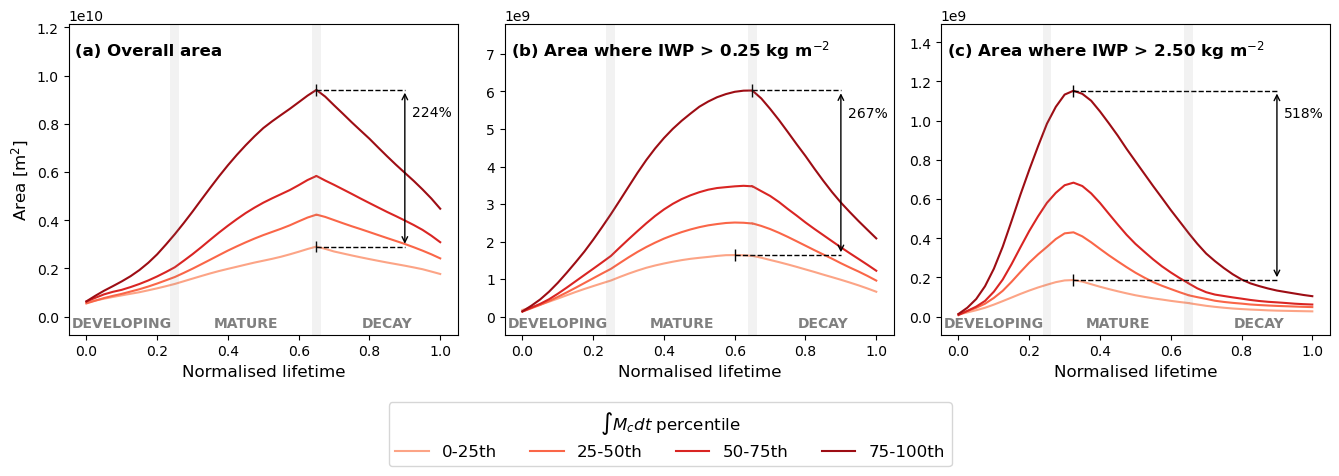

In [13]:
# data
thresholds = [0.25, 2.5]
phases = ["developing", "mature", "decay"]

# process
pdata = helpers.group_dataset_by_intensity(
    ds[["cloud_area", "thick_area", "anvil_area"]],
    df,
    apply=lambda x: x.mean("system", keep_attrs=True),
)[key]

# figure
nplots = len(thresholds) + 1
fig, axs = plt.subplots(1, nplots, figsize=(nplots * 4.5, 4), layout="tight")
axs = np.atleast_1d(axs)

handles = None
labels = None

for i, ax in enumerate(axs):
    line_lo = None
    line_hi = None

    if i == 0:
        data = pdata.anvil_area.sel(phase=phases)
        threshold_label = None
    else:
        threshold = thresholds[i - 1]
        data = pdata.thick_area.sel(threshold=threshold, phase=phases)
        threshold_label = threshold

    for j, b in enumerate(pdata.bins.values):
        color = CMAP(j / 4 + 0.1)
        evolution = plot_helpers.get_evolution(data.sel(bins=b))
        line = evolution.plot(ax=ax, c=color, label=f"{b}th", lw=1.5)

        if j == 0:
            line_lo = line[0]
        if j == len(pdata.bins.values) - 1:
            line_hi = line[0]

    y_lo = line_lo.get_ydata().max()
    x_lo = line_lo.get_xdata()[line_lo.get_ydata().argmax()]
    y_hi = line_hi.get_ydata().max()
    x_hi = line_hi.get_xdata()[line_hi.get_ydata().argmax()]

    plot_helpers.annotate_arrow(ax, 0.9, y_lo, y_hi, x_lo=x_lo, x_hi=x_hi)
    plot_helpers.show_phases(ax)

    title = (
        f"({letters[i]}) Overall area"
        if i == 0
        else f"({letters[i]}) Area where IWP > {threshold_label:.2f} kg m$^{{-2}}$"
    )
    ax.text(
        0.015,
        0.9,
        title,
        c="k",
        weight="bold",
        fontsize=fs,
        transform=ax.transAxes,
    )

    ax.set_xlabel("Normalised lifetime", fontsize=fs)
    ax.set_ylabel("Area [m$^2$]" if i == 0 else None, fontsize=fs)
    ax.set_title(None)
    ymax = ax.get_ylim()[1]
    ax.set_ylim(ymax * -0.075, ymax * 1.2)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

legend = fig.legend(
    handles,
    labels,
    title=r"$\int M_c dt$ percentile",
    fontsize=fs,
    loc="center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=4,
    frameon=True,
)
legend.get_title().set_fontsize(fs)

fig.savefig(paperdir / f"fig02.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


#### FIGURE 3

In [14]:
# calcualte the percentage increases

threshold = 2.5

def get_data_by_metric(ds, metric):
    def drop_nan(d):
        d = d.values.ravel()
        return d[~np.isnan(d)]

    ds["thick_proportion"] = ds.total_thick_area / ds.total_cloud_area
    grouped = helpers.group_dataset_by_intensity(
        ds[["total_thick_area", "total_cloud_area", "thick_proportion"]],
        df,
    )[metric]

    return [drop_nan(grouped.thick_proportion.sel(bins=b, threshold=threshold)) for b in grouped.bins]

plot_data = ["total_CMT", "max_CMT", "max_CMF", "max_w", "max_Ac", "conv_lifetime",]

percentage_increase = {}
for i, k in enumerate(plot_data):
    data = get_data_by_metric(ds, k)
    y25_mu = np.mean(data[0])
    y75_mu = np.mean(data[-1])
    percentage_increase[k] = (y75_mu - y25_mu) / y25_mu * 100

percentage_increase = pd.DataFrame(percentage_increase, ["data"]).loc["data"].sort_values(ascending=False)
percentage_increase

total_CMT        120.642888
max_CMT           81.500745
conv_lifetime     50.028435
max_Ac            24.694652
max_CMF           19.861620
max_w             15.349317
Name: data, dtype: float64

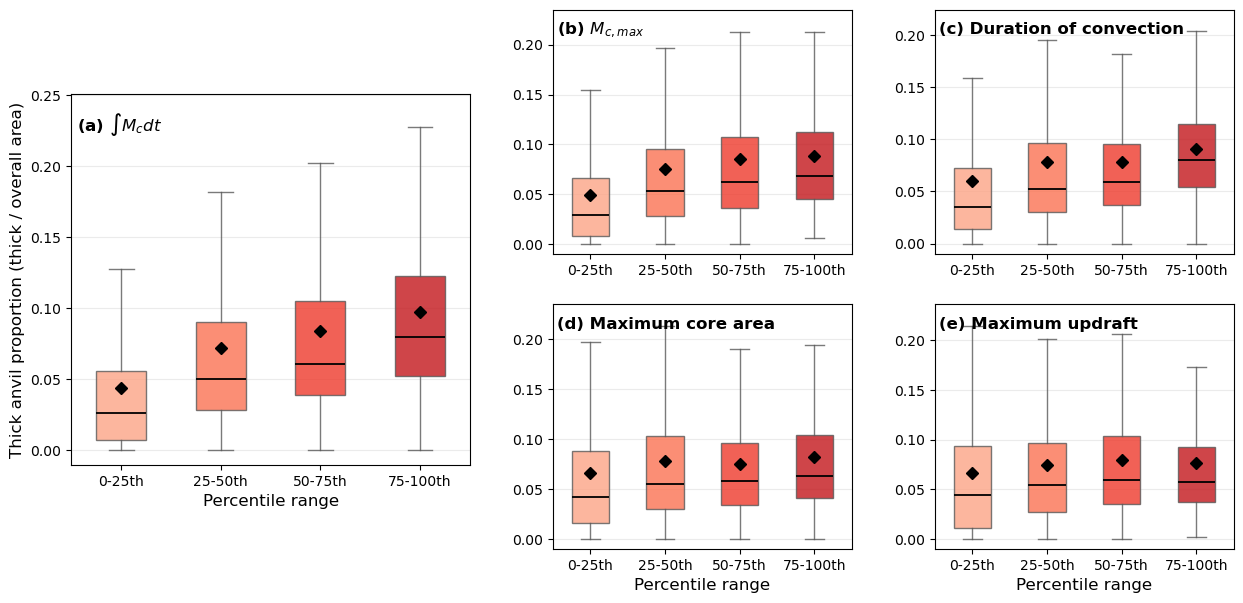

In [15]:
# plot distribution changes

threshold = 2.5

order = percentage_increase.drop("max_CMF").index
labels = [global_labels[k] for k in order]

fig = plt.figure(figsize=(15, 7), layout="constrained")
nrows = 13 
gs = fig.add_gridspec(nrows,3, width_ratios=[1,.75,.75], wspace=0.25, hspace=.25) 
rbuff = 2 
r1 = int((nrows/2) - .5) 
r2 = int((nrows/2)+.5) 
axs = [fig.add_subplot(gs[rbuff:nrows-rbuff, 0]), 
       fig.add_subplot(gs[0:r1, 1]), 
       fig.add_subplot(gs[0:r1, 2]), 
       fig.add_subplot(gs[r2:, 1]), 
       fig.add_subplot(gs[r2:, 2])]

colors = [CMAP(i / 5 + 0.1) for i in range(4)]
positions = np.arange(4)
xticks = [f"{p}th" for p in ["0-25", "25-50", "50-75", "75-100"]]

for i, metric in enumerate(order):
    ax = axs[i]
    data = get_data_by_metric(ds, metric)

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.5,
        patch_artist=True,
        showfliers=False,
        showmeans=True,
        meanprops=dict(marker="D", markerfacecolor="k", markeredgecolor="k", markersize=6),
        medianprops=dict(color="k", linewidth=1.3),
        whiskerprops=dict(color="0.35", linewidth=1),
        capprops=dict(color="0.35", linewidth=1),
        boxprops=dict(linewidth=1, edgecolor="0.35"),
    )

    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.8)

    for artist in (*bp["whiskers"], *bp["caps"]):
        artist.set_alpha(0.8)

    if np.isin(i, [0,3,4]):
        ax.set_xlabel("Percentile range", fontsize=fs)
    ax.set_xticks(positions, xticks)
    ax.grid(axis="y", alpha=0.25, linewidth=0.8)

    ax.text(
        0.015,
        0.9,
        f"({letters[i]}) {labels[i]}",
        c="k",
        weight="bold",
        fontsize=fs,
        transform=ax.transAxes,
    )
    ax.set_title(None)

    _, ymax = ax.get_ylim()
    ax.set_ylim(-0.01, ymax * 1.05)

axs[0].set_ylabel("Thick anvil proportion (thick / overall area)", fontsize=fs)

fig.savefig(paperdir / f"fig03.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


#### FIGURE 4

In [14]:
# average cloud area predictions, but grouped by those with the same end point

def get_predictions_by_their_endpoint(model):
    data = ds[model].sel(phase='growing') 
    convection_end_time = data.idxmax('interp_time') 
    convection_end_time.name = "period" 
    mean_predictions = data.groupby(convection_end_time).mean()
    mean_predictions = mean_predictions.where(mean_predictions.period>0)
    n_samples = data.groupby(convection_end_time).count().max('interp_time').astype(int)
    return mean_predictions, n_samples

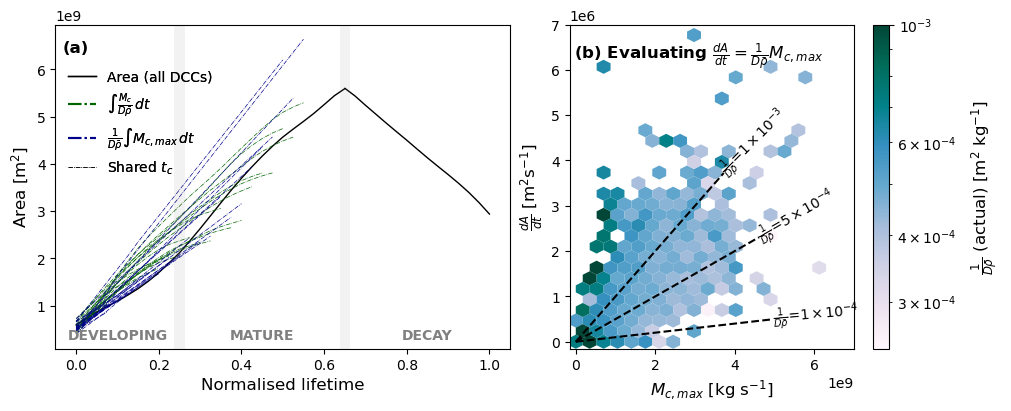

In [17]:

model_names = ("Apred_v2", "Apred_v1", )

def parallel_text(ax, xvals, yvals, label, pos=0.7, c="k", rotate=0):
    i = min(max(int(pos * (len(xvals) - 1)), 0), len(xvals) - 1)
    x0, y0 = xvals[i], yvals[i]
    ax.text(
        x0,
        y0,
        label,
        rotation=rotate,
        rotation_mode="anchor",
        transform_rotates_text=0 if rotate else None,
        c=c,
        ha="left",
        va="center",
    )

def sci_fmt(x):
    if x == 0:
        return "0"
    exp = int(np.floor(np.log10(abs(x))))
    coeff = x / 10**exp
    return rf"${coeff:.0f}\times10^{{{exp}}}$"

# figure
widths = [4, 2.5]
fig = plt.figure(figsize=(10,4), layout='constrained')
gs = fig.add_gridspec(1, len(widths), width_ratios=widths, wspace=0)
axs = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1])]

# -- first axis --
ax = axs[0]
A_mu = ds.anvil_area.mean("system")
h0 = plot_helpers.get_evolution(A_mu).plot(ax=ax, c="k", zorder=1, lw=1, label="Area (all DCCs)")

line_colors = ["darkgreen", "darkblue", ]
line_styles = ["-."] * 2

for i, model in enumerate(model_names):
    mean_predictions, n_samples = get_predictions_by_their_endpoint(model)
    label = global_labels[model]
    
    for period in mean_predictions.period.values:
        n = n_samples.sel(period=period)
        if n < 30 or period > .55:
            continue
        d = mean_predictions.sel(period=period)
        d.plot(ax=ax, lw=0.5, c=line_colors[i], ls=line_styles[i], zorder=1, label=label)
        label = None

plot_helpers.show_phases(ax, ax.get_ylim()[1] * 0.075)
ax.set_xlabel("Normalised lifetime", fontsize=fs)
ax.set_ylabel("Area [m$^2$]", fontsize=fs)
ax.set_title(None)
ax.text(
    0.015,
    0.95,
    "(a)",
    transform=ax.transAxes,
    c="k",
    weight="bold",
    fontsize=fs,
    va="top",
)

h1 = mpl.lines.Line2D([], [], color=line_colors[0], ls=line_styles[0], label=global_labels[model_names[0]])
h2 = mpl.lines.Line2D([], [], color=line_colors[1], ls=line_styles[1], label=global_labels[model_names[1]])
h3 = mpl.lines.Line2D([], [], color="k", ls=line_styles[0], lw=.5, label="Shared $t_c$")
legend = ax.legend(handles=[h0[0],h1,h2,h3], loc="upper left", bbox_to_anchor=(0.0, 0.9), frameon=False, fontsize=fs - 2, ncol=1)
ax.add_artist(legend)

# -- second axis --
ax = axs[1]
scale_func = r"$\frac{1}{D\bar{\rho}}$"
scmap = plt.get_cmap("PuBuGn")

# estimate dA/dt
d = ds.sel(phase="growing")
A = d.cloud_area
tmax = (d.lifetime.mean("system") * 60 * 60) * 0.65 # mean duration of the growth phase in seconds
A = A.assign_coords(interp_time=np.linspace(0, tmax, A.interp_time.size))
dAdt = A.differentiate("interp_time").mean("interp_time")
c_vals = 1 / (d.anvil_depth_mu.max("interp_time") * d.anvil_rho.mean("interp_time"))

# show relationship
x, y, xline, yline, m, r = helpers.evaluate_predictions(ds.max_CMT, dAdt)
xmin, xmax = np.min(x), np.max(x)

hb = ax.hexbin(
    x,
    y,
    C=c_vals.values,
    reduce_C_function=np.mean,
    gridsize=(20, 15),
    mincnt=1,
    extent=(0, 7e9, 0, 7e6),
    cmap=scmap,
    norm=mpl.colors.LogNorm(vmax=1e-3),
    linewidths=0,
    edgecolors="none",
)

# add analytical relationship
scalings = [1e-3, 5e-4, 1e-4]
fractions = [0.525, 0.65, 0.7] # how to place text
rotations = [45, 30, 5]

for scaling, frac, rotation in zip(scalings, fractions, rotations):
    x_vals = np.linspace(xmin, xmax * frac, 10)
    y_vals = scaling * x_vals
    ax.plot(x_vals, y_vals, c="k", ls="--", lw=1.5)
    parallel_text(
        ax,
        x_vals,
        y_vals,
        label=f"{scale_func}={sci_fmt(scaling)}",
        pos=1,
        c="k",
        rotate=rotation,
    )

ax.set_xlim(-0.15e9, 7e9)
ax.set_ylim(-0.15e6, 7e6)
ax.set_xlabel(r"$M_{c,max}$ [kg s$^{-1}$]", fontsize=fs)
ax.set_ylabel(r"$\frac{dA}{dt}$ [m$^2$s$^{-1}$]", fontsize=fs)
ax.set_title(None)
ax.text(
    0.015,
    0.95,
    r"(b) Evaluating $\frac{dA}{dt}=\frac{1}{D\bar{\rho}}M_{c,max}$",
    transform=ax.transAxes,
    c="k",
    weight="bold",
    fontsize=fs,
    va="top",
)

cbar = fig.colorbar(hb, ax=axs[1], location="right", orientation="vertical", )
cbar.set_label(scale_func + r" (actual) [m$^2$ kg$^{-1}$]", fontsize=fs, labelpad=10)

fig.savefig(paperdir / f"fig04.{ext}", bbox_inches="tight", dpi=dpi)

#### FIGURE 5

In [6]:
# data
model_data = ds[['cloud_area', 'thick_area', 'Apred_v2_cont', 'core_rho_ABH', 'core_area_ABH',
                 'core_fwc_ABH', 'core_cmt_ABH', 'anvil_depth_mu', 'anvil_rho', 'lifetime']]
model_data_by_inflow = helpers.group_dataset_by_intensity(model_data, df)[key]

# model choice for area evolution
A_model = "Apred_v2_cont"

In [7]:
# input values, averaged within each inflow quartile
broadcast = model_data.cloud_area.mean('system')
A = model_data_by_inflow[A_model]
Ac = model_data_by_inflow.core_area_ABH
D = model_data_by_inflow.anvil_depth_mu
fwc = model_data_by_inflow.core_fwc_ABH

# input values, averaged across all data
D_mu = model_data.anvil_depth_mu.mean('system')
fwc_mu = model_data.core_fwc_ABH.mean('system')

# modify predicted area with fixed depth
Apred_fixed_D = A * D / D_mu # where A = 1 / (rho D) * integral (CMF) dt

In [8]:
# best case (everything varies)

n = 1
tau = 1

best = analytical.Thickness(model_data_by_inflow, pred=A_model, n=n, tau=tau)

In [9]:
# vary depth only

vdepth_input = model_data_by_inflow.copy()

vdepth_input[A_model] = A
vdepth_input['core_area_ABH'] = Ac
vdepth_input['anvil_depth_mu'] = D
vdepth_input['core_fwc_ABH'] = fwc_mu

vary_depth = analytical.Thickness(vdepth_input, pred=A_model, n=n, tau=tau)


In [10]:
# vary IWC only

viwc_input = model_data_by_inflow.copy()

viwc_input[A_model] = Apred_fixed_D
viwc_input['core_area_ABH'] = Ac
viwc_input['anvil_depth_mu'] = D_mu
viwc_input['core_fwc_ABH'] = fwc

vary_iwc = analytical.Thickness(viwc_input, pred=A_model, n=n, tau=tau)


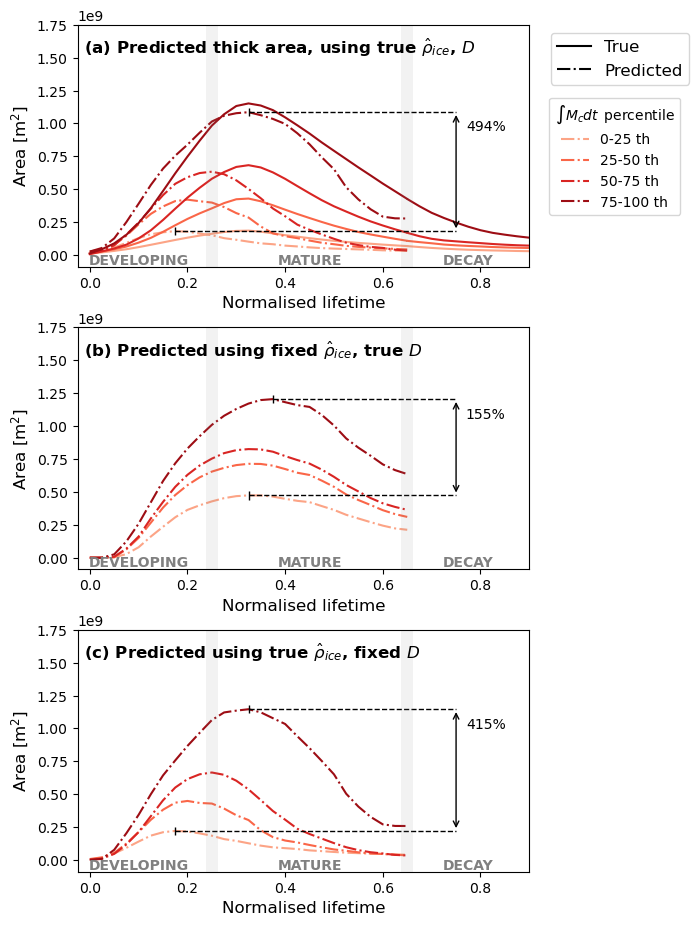

In [12]:
x = 2.5 # IWP threshold
    
# figure
fig = plt.figure(figsize=(6.5, 11))
outer = fig.add_gridspec(3,1, wspace=.4, hspace=.25,)

axs = []
for i in range(3):
    axs.append(fig.add_subplot(outer[i]))

#### -- show the predictions -- ####

# plot
for j,b in enumerate(model_data_by_inflow.bins.values):
    c = CMAP(j/4+.1)
    thick_evolution = plot_helpers.get_evolution(model_data_by_inflow.thick_area.sel(bins=b, threshold=x).mean('system'))
    thick_evolution.plot(ax=axs[0], c=c, lw=1.5)
    dbest = best.thick_A.sel(threshold=x).mean('system')
    dbest.sel(bins=b).plot(ax=axs[0], c=c, label='%s th' %b, lw=1.5, ls='-.')

    d2 = vary_depth.thick_A.sel(threshold=x).mean('system')
    d2.sel(bins=b).plot(ax=axs[1], c=c, label='%s th' %b, lw=1.5, ls='-.')
    
    d3 = vary_iwc.thick_A.sel(threshold=x).mean('system')
    d3.sel(bins=b).plot(ax=axs[2], c=c, label='%s th' %b, lw=1.5, ls='-.')

# scaling
plot_helpers.annotate_arrow(axs[0], 0.75, 
                            dbest.isel(bins=0).max(), dbest.isel(bins=-1).max(), 
                            dbest.isel(bins=0).idxmax(), dbest.isel(bins=-1).idxmax())
plot_helpers.annotate_arrow(axs[1], 0.75, d2.isel(bins=0).max(), d2.isel(bins=-1).max(),
                            d2.isel(bins=0).idxmax(), d2.isel(bins=-1).idxmax())
plot_helpers.annotate_arrow(axs[2], 0.75, d3.isel(bins=0).max(), d3.isel(bins=-1).max(),
                            d3.isel(bins=0).idxmax(), d3.isel(bins=-1).idxmax())

# decorate
titles = [r'Predicted thick area, using true $\hat{\rho}_{ice}$, $D$', 
          r'Predicted using fixed $\hat{\rho}_{ice}$, true $D$', 
          r'Predicted using true $\hat{\rho}_{ice}$, fixed $D$', ]
yloc = 1e7
count = 0
handles = None
for ax in axs:
    # title
    tparams = dict(c='k', weight='bold', fontsize=fs, transform=ax.transAxes, va='top')
    title = f'({letters[count]}) {titles[count]}'
    ax.text(0.015, .95, title, **tparams)
    ax.set_title(None)
    # more
    plot_helpers.show_phases(ax, .0125e9, (.1,.45,.775))
    ymax = 1.75e9
    ax.set_ylim(ymax*-.05, ymax)
    ax.set_xlim(-.025,.9)
    ax.set_xlabel('Normalised lifetime', fontsize=fs)
    ax.set_ylabel('Area [m$^2$]', fontsize=fs)
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    count += 1

# legend
fig.subplots_adjust(right=0.82)
fig.legend(handles, labels, title="$\int M_c dt\,$ percentile",
           fontsize=fs-2, loc='upper left', bbox_to_anchor=(0.84, 0.82))
fig.legend(handles=[mpl.lines.Line2D([], [], ls='-', c='k', label='True'),
                    mpl.lines.Line2D([], [], ls='-.', c='k', label='Predicted')],
           fontsize=fs, loc='upper left', bbox_to_anchor=(0.84, 0.88))

# save
fig.savefig(paperdir / f'fig05.{ext}', bbox_inches='tight', dpi=dpi, transparent=0)
    